[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/08-ai-engineering/08_multimodal.ipynb)

*AI Engineering · Notebook 8 of 9*

# Multimodal AI: Images, Documents & Speech

Build with images, PDFs and audio: how images become tokens and what they cost, resizing and patches, sending images to an API, document AI (reading order, tables, field validation, page routing), speech (framing, chunking, WER, subtitles), CLIP-style zero-shot labels, voice-agent latency and video frames.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** To a model, an image is a grid of word-like patches and audio is a strip of short frames — all of them end up as tokens.

**What interviewers really test here:** Image token cost, patches, document extraction and validation, WER, voice latency budgets and zero-shot labels.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. How a model sees an image *(Basics)*
- [ ] 2. Inside the pipeline: patches, normalisation, embeddings *(Core)*
- [ ] 3. Document AI: PDFs, scans, tables and forms *(Core)*
- [ ] 4. Speech: from audio to text and back *(Core)*
- [ ] 5. Voice agents and video *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import json
import numpy as np
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Modalities at a glance

| Input | Becomes | Watch out for |
| --- | --- | --- |
| Image | patch embeddings (tokens ∝ pixels) | cost of big images; tiny text in screenshots |
| PDF / scan | text layer, OCR, or page images | reading order, tables, handwriting |
| Audio | frames → spectrogram → tokens or text | chunk boundaries, accents, noise, latency |
| Video | sampled frames + transcript | token budget, missing fast events |

### Architectures

- **Vision encoder + LLM**: a ViT turns images into embeddings that are projected into the LLM's token space.
- **Contrastive (CLIP-style)**: separate image and text encoders trained so matching pairs have similar embeddings — great for search and zero-shot labels.
- **Speech**: encoder–decoder transcription models; speech-to-speech models handle audio end to end.

---
# Part 2: Lessons, step by step

## Lesson 1: How a model sees an image

*Level: Basics*

A vision-language model cuts an image into small square **patches** (e.g. 14×14 pixels), turns each patch into a vector, and feeds those vectors to the transformer alongside text tokens. So an image **costs tokens** — roughly in proportion to its pixel area (Claude's documented estimate: width × height ÷ 750), and very large images are downscaled first.



Practical rules: resize before sending (saves upload time and tokens), crop to what matters, put images **before** the question about them, and label several images ("Image 1:", "Image 2:").



```python
import base64
data = base64.b64encode(open("chart.png", "rb").read()).decode()
client.messages.create(model="claude-opus-5-5", max_tokens=500, messages=[{"role": "user", "content": [
    {"type": "image", "source": {"type": "base64", "media_type": "image/png", "data": data}},
    {"type": "text", "text": "What trend does this chart show?"}]}])
```

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

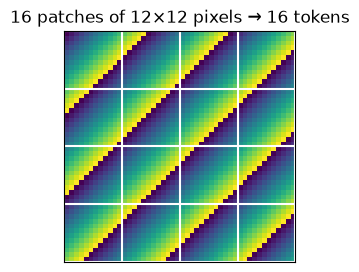

In [2]:
import matplotlib.pyplot as plt


def patch_grid():
    img = np.add.outer(np.arange(48), np.arange(48)) % 17
    fig, ax = plt.subplots(figsize=(3, 3))
    ax.imshow(img, cmap="viridis")
    for k in range(0, 49, 12):
        ax.axhline(k - 0.5, color="white"); ax.axvline(k - 0.5, color="white")
    ax.set_title("16 patches of 12×12 pixels → 16 tokens")
    ax.set_xticks([]); ax.set_yticks([])


patch_grid()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 2: Inside the pipeline: patches, normalisation, embeddings

*Level: Core*

Before a vision model sees pixels, they're scaled to 0–1 and normalised per channel with the mean and standard deviation the model was trained with. Patches are flattened into vectors and projected to embeddings — the same "everything is a sequence of vectors" idea as text.



**Image embeddings** (CLIP-style models) put images and text into one vector space, so you can search images with text, find similar images, or classify with **zero-shot labels** ("a photo of a cat" vs "a scanned document") — no training needed.

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q4](#q4), [Q10](#q10), [Q17](#q17). Try one now, or carry on and do them in Part 3.

## Lesson 3: Document AI: PDFs, scans, tables and forms

*Level: Core*

Real business data is PDFs, scans, invoices and slide decks. Two routes, often combined:




- **Text route**: extract text (PDF text layer or OCR), restore reading order (OCR returns words with positions, not sentences), turn tables into Markdown, chunk with page numbers for citations.
- **Vision route**: send the page image (or the whole PDF — Claude accepts PDFs as document blocks) when layout, charts or handwriting matter.



Route per page: text for dense prose, images for charts and scans. When a model extracts fields (invoice number, totals), **validate them in code** — required fields, valid dates, line items that add up — and send failures for review instead of trusting them.

**✏️ Your turn:** you now have what you need for [Q15](#q15), [Q8](#q8), [Q16](#q16), [Q9](#q9), [Q11](#q11). Try one now, or carry on and do them in Part 3.

## Lesson 4: Speech: from audio to text and back

*Level: Core*

Audio is a long list of samples (16,000 per second is common for speech). Models analyse it in short overlapping **frames** (25 ms every 10 ms) turned into spectrogram features. Speech-to-text models (such as the open-source Whisper family, or hosted transcription APIs) accept limited lengths, so long recordings are split into **overlapping chunks** and stitched back together.



Measure transcription quality with **word error rate** (the edit distance between word lists divided by the reference length), and produce subtitles with timestamps (SRT/VTT).

**✏️ Your turn:** you now have what you need for [Q6](#q6), [Q13](#q13), [Q14](#q14), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 5: Voice agents and video

*Level: Advanced*

A **voice agent** listens, thinks and speaks. The classic **cascade** is: voice activity detection (has the user finished?) → speech-to-text → LLM → text-to-speech. **Speech-to-speech** models do it in one model, with lower latency and more natural prosody. Either way, latency is everything: aim for the first audio within about 800 ms by streaming every stage, using a fast model, and starting text-to-speech on the first sentence. Good turn detection — not cutting people off, not waiting too long — matters as much as model quality.



**Video** is usually handled as sampled frames (images) plus the audio transcript. Sample sparsely to fit the token budget; sample densely only around moments that matter.

**✏️ Your turn:** you now have what you need for [Q18](#q18), [Q20](#q20), [Q19](#q19). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. What Does an Image Cost?

🟢 Warm-up · *Image tokens*

Using the estimate tokens ≈ width × height / 750 (rounded up), return tokens and dollars for each image size at `price` per million input tokens (dollars rounded to 4).

**Examples**

- `sizes = [(1092, 1092), (800, 600), (200, 200)], price = 3.0` → `[(1590, 0.0048), (640, 0.0019), (54, 0.0002)]`

In [ ]:
def image_cost(sizes, price):
    """
    Using the estimate tokens ≈ width × height / 750 (rounded up), return tokens
    and dollars for each image size at price per million input tokens (dollars
    rounded to 4).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(image_cost, [
    (([(1092, 1092), (800, 600), (200, 200)], 3.0), [(1590, 0.0048), (640, 0.0019), (54, 0.0002)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension with `math.ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop.

```python
def image_cost(sizes, price):
    out = []
    for w, h in sizes:
        t = w * h // 750
        if w * h % 750:
            t += 1
        out.append((t, round(t * price / 1e6, 4)))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension with `math.ceil`.

```python
def image_cost(sizes, price):
    return [(t, round(t * price / 1e6, 4)) for t in (math.ceil(w * h / 750) for w, h in sizes)]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension with `math.ceil`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/what-does-an-image-cost)

<a id="q2"></a>
### Q2. Resize Before Sending

🟢 Warm-up · *Keep the aspect ratio*

Large images get downscaled by the API anyway (and cost more to upload). Shrink so the long edge is at most `max_edge`, keeping the aspect ratio (round down); smaller images stay as they are.

**Examples**

- `size = (4032, 3024), max_edge = 1568` → `(1568, 1176)`
- `size = (1000, 3000), max_edge = 1568` → `(522, 1568)`
- `size = (640, 480), max_edge = 1568` → `(640, 480)`

In [ ]:
def resize(size, max_edge):
    """
    Large images get downscaled by the API anyway (and cost more to upload).
    Shrink so the long edge is at most max_edge, keeping the aspect ratio (round
    down); smaller images stay as they are.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(resize, [
    (((4032, 3024), 1568), (1568, 1176)),
    (((1000, 3000), 1568), (522, 1568)),
    (((640, 480), 1568), (640, 480)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute the scale with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Integer arithmetic `v * max_edge // long_edge` avoids floating-point rounding surprises.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute the scale with an if.

```python
def resize(size, max_edge):
    w, h = size
    long_edge = w if w > h else h
    if long_edge <= max_edge:
        return (w, h)
    return (w * max_edge // long_edge, h * max_edge // long_edge)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Integer arithmetic `v * max_edge // long_edge` avoids floating-point rounding surprises.

```python
def resize(size, max_edge):
    long_edge = max(size)
    return size if long_edge <= max_edge else tuple(v * max_edge // long_edge for v in size)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute the scale with an if. That costs O(1) time and O(1) space."

"I can do better: Integer arithmetic `v * max_edge // long_edge` avoids floating-point rounding surprises. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/resize-before-sending)

<a id="q3"></a>
### Q3. How Many Patches?

🟢 Warm-up · *Vision transformers*

A vision transformer splits an image into p×p patches (padding the edges). Return `(patches, patches after resizing to `target`×`target`)`.

**Examples**

- `size = (224, 224), p = 16, target = 224` → `(196, 196)`
- `size = (1000, 750), p = 14, target = 336` → `(3888, 576)`

In [ ]:
def patches(size, p, target):
    """
    A vision transformer splits an image into p×p patches (padding the edges).
    Return (patches, patches after resizing to target×target).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(patches, [
    (((224, 224), 16, 224), (196, 196)),
    (((1000, 750), 14, 336), (3888, 576)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Ceiling division by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`math.ceil`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Ceiling division by hand.

```python
def patches(size, p, target):
    w, h = size
    cols = w // p + (1 if w % p else 0)
    rows = h // p + (1 if h % p else 0)
    t = target // p + (1 if target % p else 0)
    return (cols * rows, t * t)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `math.ceil`.

```python
def patches(size, p, target):
    return (math.ceil(size[0] / p) * math.ceil(size[1] / p), math.ceil(target / p) ** 2)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Ceiling division by hand. That costs O(1) time and O(1) space."

"I can do better: `math.ceil`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/how-many-patches)

<a id="q4"></a>
### Q4. Normalise Pixels

🟢 Warm-up · *Model input preprocessing*

Scale RGB pixels from 0–255 to 0–1, then normalise each channel with the given mean and std. Return the normalised pixels rounded to 3.

**Examples**

- `pixels = [[255, 128, 0], [10, 200, 90]], mean = [0.485, 0.456, 0.406], std = [0.229, 0.224, 0.225]` → `[[2.249, 0.205, -1.804], [-1.947, 1.466, -0.236]]`

In [ ]:
def normalise(pixels, mean, std):
    """
    Scale RGB pixels from 0–255 to 0–1, then normalise each channel with the
    given mean and std. Return the normalised pixels rounded to 3.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(normalise, [
    (([[255, 128, 0], [10, 200, 90]], [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]), [[2.249, 0.205, -1.804], [-1.947, 1.466, -0.236]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over pixels and channels.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy broadcasting.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops over pixels and channels.

```python
def normalise(pixels, mean, std):
    out = []
    for px in pixels:
        out.append([round((px[c] / 255 - mean[c]) / std[c], 3) for c in range(3)])
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy broadcasting.

```python
def normalise(pixels, mean, std):
    return np.round((np.array(pixels) / 255 - np.array(mean)) / np.array(std), 3).tolist()
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over pixels and channels. That costs O(n) time and O(n) space."

"I can do better: NumPy broadcasting. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/normalise-pixels)

<a id="q5"></a>
### Q5. Build an Image Content Block

🟢 Warm-up · *Sending images to the API*

Return the Claude API image content block for a file: base64-encode the bytes, and set `media_type` from the extension (.png, .jpg/.jpeg, .gif, .webp). Unsupported types return None.

**Examples**

- `name = 'chart.png', data = b'\x89PNG...'` → `{'type': 'image', 'source': {'type': 'base64', 'media_type': 'image/png', 'data': 'iVBORy4uLg=='}}`
- `name = 'photo.JPG', data = b'\xff\xd8\xff'` → `{'type': 'image', 'source': {'type': 'base64', 'media_type': 'image/jpeg', 'data': '/9j/'}}`
- `name = 'scan.tiff', data = b'II*'` → `None`

In [ ]:
import base64

def image_block(name, data):
    """
    Return the Claude API image content block for a file: base64-encode the
    bytes, and set media_type from the extension (.png, .jpg/.jpeg, .gif,
    .webp). Unsupported types return None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(image_block, [
    (('chart.png', b'\x89PNG...'), {'type': 'image', 'source': {'type': 'base64', 'media_type': 'image/png', 'data': 'iVBORy4uLg=='}}),
    (('photo.JPG', b'\xff\xd8\xff'), {'type': 'image', 'source': {'type': 'base64', 'media_type': 'image/jpeg', 'data': '/9j/'}}),
    (('scan.tiff', b'II*'), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

An if-chain on the lower-cased extension.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dict lookup.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** An if-chain on the lower-cased extension.

```python
def image_block(name, data):
    ext = name.lower().rsplit(".", 1)[-1]
    if ext == "png":
        mt = "image/png"
    elif ext in ("jpg", "jpeg"):
        mt = "image/jpeg"
    elif ext == "gif":
        mt = "image/gif"
    elif ext == "webp":
        mt = "image/webp"
    else:
        return None
    return {"type": "image", "source": {"type": "base64", "media_type": mt, "data": base64.b64encode(data).decode()}}
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dict lookup.

```python
def image_block(name, data):
    types = {"png": "image/png", "jpg": "image/jpeg", "jpeg": "image/jpeg", "gif": "image/gif", "webp": "image/webp"}
    mt = types.get(name.lower().rsplit(".", 1)[-1])
    return {"type": "image", "source": {"type": "base64", "media_type": mt, "data": base64.b64encode(data).decode()}} if mt else None
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: An if-chain on the lower-cased extension. That costs O(n) time and O(n) space."

"I can do better: A dict lookup. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/build-an-image-content-block)

<a id="q6"></a>
### Q6. Slice Audio Into Frames

🟢 Warm-up · *Speech features*

Audio at `sr` samples per second is analysed in windows of `win_ms` milliseconds every `hop_ms`. Return `(samples, duration in seconds rounded to 2, number of full frames)` for `n_samples`.

**Examples**

- `sr = 16000, n_samples = 48000, win_ms = 25, hop_ms = 10` → `(48000, 3.0, 298)`
- `sr = 16000, n_samples = 300, win_ms = 25, hop_ms = 10` → `(300, 0.02, 0)`

In [ ]:
def frames(sr, n_samples, win_ms, hop_ms):
    """
    Audio at sr samples per second is analysed in windows of win_ms milliseconds
    every hop_ms. Return (samples, duration in seconds rounded to 2, number of
    full frames) for n_samples.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(frames, [
    ((16000, 48000, 25, 10), (48000, 3.0, 298)),
    ((16000, 300, 25, 10), (300, 0.02, 0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Convert ms to samples, then count frames with a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Closed form 1 + (n − win) // hop.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Convert ms to samples, then count frames with a loop.

```python
def frames(sr, n_samples, win_ms, hop_ms):
    win, hop = sr * win_ms // 1000, sr * hop_ms // 1000
    count, start = 0, 0
    while start + win <= n_samples:
        count += 1
        start += hop
    return (n_samples, round(n_samples / sr, 2), count)
```

**Cost:** O(frames) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Closed form 1 + (n − win) // hop.

```python
def frames(sr, n_samples, win_ms, hop_ms):
    win, hop = sr * win_ms // 1000, sr * hop_ms // 1000
    return (n_samples, round(n_samples / sr, 2), max(0, 1 + (n_samples - win) // hop))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Convert ms to samples, then count frames with a loop. That costs O(frames) time and O(1) space."

"I can do better: Closed form 1 + (n − win) // hop. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/slice-audio-into-frames)

<a id="q7"></a>
### Q7. Write Subtitles

🟢 Warm-up · *Timestamps*

Turn transcript segments `(start_s, end_s, text)` into SRT blocks: index, then `HH:MM:SS,mmm --> HH:MM:SS,mmm`, then the text, separated by blank lines.

**Examples**

- `segments = [(0.0, 2.5, 'Hello and welcome.'), (2.5, 65.25, 'Today: multimodal AI.')]` → `'1\n00:00:00,000 --> 00:00:02,500\nHello and welcome.\n\n2\n00:00:02,500 --> 00:01:05,250\nToday: multimodal AI.'`

In [ ]:
def srt(segments):
    """
    Turn transcript segments (start_s, end_s, text) into SRT blocks: index, then
    HH:MM:SS,mmm --> HH:MM:SS,mmm, then the text, separated by blank lines.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(srt, [
    (([(0.0, 2.5, 'Hello and welcome.'), (2.5, 65.25, 'Today: multimodal AI.')],), '1\n00:00:00,000 --> 00:00:02,500\nHello and welcome.\n\n2\n00:00:02,500 --> 00:01:05,250\nToday: multimodal AI.'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Format each time with divmod by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A helper with f-string zero-padding.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Format each time with divmod by hand.

```python
def srt(segments):
    def ts(sec):
        ms = int(round(sec * 1000))
        h = ms // 3600000
        ms -= h * 3600000
        m = ms // 60000
        ms -= m * 60000
        s = ms // 1000
        ms -= s * 1000
        return str(h).zfill(2) + ":" + str(m).zfill(2) + ":" + str(s).zfill(2) + "," + str(ms).zfill(3)
    blocks = []
    for i, (a, b, text) in enumerate(segments, 1):
        blocks.append(str(i) + "\n" + ts(a) + " --> " + ts(b) + "\n" + text)
    return "\n\n".join(blocks)
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A helper with f-string zero-padding.

```python
def srt(segments):
    def ts(sec):
        ms = round(sec * 1000)
        h, ms = divmod(ms, 3_600_000)
        m, ms = divmod(ms, 60_000)
        s, ms = divmod(ms, 1000)
        return f"{h:02}:{m:02}:{s:02},{ms:03}"
    return "\n\n".join(f"{i}\n{ts(a)} --> {ts(b)}\n{t}" for i, (a, b, t) in enumerate(segments, 1))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Format each time with divmod by hand. That costs O(n) time and O(n) space."

"I can do better: A helper with f-string zero-padding. That's O(n) time and O(n) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `segments = [(0.0, 2.5, 'Hello and welcome.')]`

1. ts() returns '00:00:00,000'
2. ts() returns '00:00:02,500'
3. srt() returns '1\\n00:00:00,000 --&gt; 00:00:02,500\\nHe...

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/write-subtitles)

<a id="q8"></a>
### Q8. Table Rows to Markdown

🟢 Warm-up · *Giving tables to an LLM*

Models read tables best as Markdown. Convert rows (the first is the header) into a Markdown table string, with cells separated by ' | ' and a '---' separator row.

**Examples**

- `rows = [['Item', 'Qty', 'Price'], ['Pen', '10', '5'], ['Book', '2', '120']]` → `'| Item | Qty | Price |\n| --- | --- | --- |\n| Pen | 10 | 5 |\n| Book | 2 | 120 |'`

In [ ]:
def to_markdown(rows):
    """
    Models read tables best as Markdown. Convert rows (the first is the header)
    into a Markdown table string, with cells separated by ' | ' and a '---'
    separator row.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_markdown, [
    (([['Item', 'Qty', 'Price'], ['Pen', '10', '5'], ['Book', '2', '120']],), '| Item | Qty | Price |\n| --- | --- | --- |\n| Pen | 10 | 5 |\n| Book | 2 | 120 |'),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

String building in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Joins.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** String building in loops.

```python
def to_markdown(rows):
    lines = []
    for i, row in enumerate(rows):
        lines.append("| " + " | ".join(row) + " |")
        if i == 0:
            seps = []
            for _ in row:
                seps.append("---")
            lines.append("| " + " | ".join(seps) + " |")
    return "\n".join(lines)
```

**Cost:** O(cells) time, O(cells) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Joins.

```python
def to_markdown(rows):
    line = lambda cells: "| " + " | ".join(cells) + " |"
    return "\n".join([line(rows[0]), line(["---"] * len(rows[0]))] + [line(r) for r in rows[1:]])
```

**Cost:** O(cells) time, O(cells) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: String building in loops. That costs O(cells) time and O(cells) space."

"I can do better: Joins. That's O(cells) time and O(cells) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/table-rows-to-markdown)

<a id="q9"></a>
### Q9. Text or Image for Each Page?

🟢 Warm-up · *Multimodal RAG routing*

`pages` are (extracted characters, figures). For PDF pages, plain extracted text is cheap, but pages that are mostly charts, scans or diagrams need the page image. Send the image if the page has fewer than `min_chars` extracted characters or more than `max_figures` figures. Return 'text' or 'image' per page.

**Examples**

- `pages = [(2400, 0), (120, 1), (1800, 3), (60, 0)], min_chars = 300, max_figures = 2` → `['text', 'image', 'image', 'image']`

In [ ]:
def page_mode(pages, min_chars, max_figures):
    """
    pages are (extracted characters, figures). For PDF pages, plain extracted
    text is cheap, but pages that are mostly charts, scans or diagrams need the
    page image. Send the image if the page has fewer than min_chars extracted
    characters or more than max_figures figures. Return 'text' or 'image' per
    page.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(page_mode, [
    (([(2400, 0), (120, 1), (1800, 3), (60, 0)], 300, 2), ['text', 'image', 'image', 'image']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with an if.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with an if.

```python
def page_mode(pages, min_chars, max_figures):
    out = []
    for chars, figs in pages:
        if chars < min_chars or figs > max_figures:
            out.append("image")
        else:
            out.append("text")
    return out
```

**Cost:** O(p) time, O(p) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def page_mode(pages, min_chars, max_figures):
    return ["image" if c < min_chars or f > max_figures else "text" for c, f in pages]
```

**Cost:** O(p) time, O(p) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with an if. That costs O(p) time and O(p) space."

"I can do better: A comprehension. That's O(p) time and O(p) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/text-or-image-for-each-page)

<a id="q10"></a>
### Q10. Find Similar Images

🟢 Warm-up · *Image embeddings*

Images are embedded as vectors; similar images point the same way. Return the ids of the `k` images most similar (cosine) to `query`, excluding itself.

**Examples**

- `query = 'cat_photo', k = 2` → `['dog_photo', 'chart']`
- `query = 'invoice_scan', k = 1` → `['chart']`

In [ ]:
EMB = {"cat_photo": [0.9, 0.1, 0.0], "dog_photo": [0.7, 0.6, 0.1], "invoice_scan": [0.0, 0.2, 0.95], "chart": [0.1, 0.1, 0.8]}

def similar_images(query, k):
    """
    Images are embedded as vectors; similar images point the same way. Return
    the ids of the k images most similar (cosine) to query, excluding itself.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(similar_images, [
    (('cat_photo', 2), ['dog_photo', 'chart']),
    (('invoice_scan', 1), ['chart']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Cosine by hand in a loop, then sort.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Normalise once with NumPy and use a matrix–vector product.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Cosine by hand in a loop, then sort.

```python
def similar_images(query, k):
    q = EMB[query]
    scores = []
    for name, v in EMB.items():
        if name == query:
            continue
        dot = sum(a * b for a, b in zip(q, v))
        cos = dot / (math.sqrt(sum(a * a for a in q)) * math.sqrt(sum(b * b for b in v)))
        scores.append((cos, name))
    scores.sort(reverse=True)
    return [n for _, n in scores[:k]]
```

**Cost:** O(n·d) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Normalise once with NumPy and use a matrix–vector product.

```python
def similar_images(query, k):
    names = [n for n in EMB if n != query]
    M = np.array([EMB[n] for n in names])
    q = np.array(EMB[query])
    sims = (M / np.linalg.norm(M, axis=1, keepdims=True)) @ (q / np.linalg.norm(q))
    return [names[i] for i in np.argsort(-sims)[:k]]
```

**Cost:** O(n·d) time, O(n·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Cosine by hand in a loop, then sort. That costs O(n·d) time and O(n) space."

"I can do better: Normalise once with NumPy and use a matrix–vector product. That's O(n·d) time and O(n·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/find-similar-images)

<a id="q11"></a>
### Q11. Chunk a PDF and Keep Page Numbers

🟢 Warm-up · *Citable document chunks*

Split each page's text into chunks of at most `max_words` words, skipping empty pages, and keep the page number (from 1) with each chunk so answers can cite 'p. 2'. Return `[(page, chunk text)]`.

**Examples**

- `pages = ['Invoice terms. Payment is due in 30 days. Late fees apply after 45 days.', 'Returns policy. Items can be returned within 10 days. Refunds take 5 to 7 business days to reach cards.', ''], max_words = 8` → `[(1, 'Invoice terms. Payment is due in 30 days.'), (1, 'Late fees apply after 45 days.'), (2, 'Returns policy. Items can be returned within 10'), (2, 'days. Refunds take 5 to 7 business days'), (2, 'to reach cards.')]`

In [ ]:
def pdf_chunks(pages, max_words):
    """
    Split each page's text into chunks of at most max_words words, skipping
    empty pages, and keep the page number (from 1) with each chunk so answers
    can cite 'p. 2'. Return [(page, chunk text)].
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(pdf_chunks, [
    ((['Invoice terms. Payment is due in 30 days. Late fees apply after 45 days.', 'Returns policy. Items can be returned within 10 days. Refunds take 5 to 7 business days to reach cards.', ''], 8), [(1, 'Invoice terms. Payment is due in 30 days.'), (1, 'Late fees apply after 45 days.'), (2, 'Returns policy. Items can be returned within 10'), (2, 'days. Refunds take 5 to 7 business days'), (2, 'to reach cards.')]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops over pages and word windows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension over `enumerate(pages, 1)` and `range` steps.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops over pages and word windows.

```python
def pdf_chunks(pages, max_words):
    out = []
    for i, text in enumerate(pages):
        words = text.split()
        start = 0
        while start < len(words):
            out.append((i + 1, " ".join(words[start:start + max_words])))
            start += max_words
    return out
```

**Cost:** O(words) time, O(words) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension over `enumerate(pages, 1)` and `range` steps.

```python
def pdf_chunks(pages, max_words):
    return [(n, " ".join(w[i:i + max_words])) for n, text in enumerate(pages, 1)
            for w in [text.split()] for i in range(0, len(w), max_words)]
```

**Cost:** O(words) time, O(words) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops over pages and word windows. That costs O(words) time and O(words) space."

"I can do better: A comprehension over `enumerate(pages, 1)` and `range` steps. That's O(words) time and O(words) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/chunk-a-pdf-and-keep-page-numbers)

<a id="q12"></a>
### Q12. Cut an Image Into Patch Vectors

🟡 Interview standard · *From pixels to tokens*

Split an H×W grey image (H, W divisible by p) into p×p patches, row by row, and flatten each into a vector. Return `(number of patches, the first two patch vectors)`.

**Examples**

- `img = [[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11], [12, 13, 14, 15, 16, 17], [18, 19, 20, 21, 22, 23], [24, 25, 26, 27, 28, 29], [30, 31, 32, 33, 34, 35]], p = 3` → `(4, [[0, 1, 2, 6, 7, 8, 12, 13, 14], [3, 4, 5, 9, 10, 11, 15, 16, 17]])`
- `img = [[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11], [12, 13, 14, 15, 16, 17], [18, 19, 20, 21, 22, 23], [24, 25, 26, 27, 28, 29], [30, 31, 32, 33, 34, 35]], p = 2` → `(9, [[0, 1, 6, 7], [2, 3, 8, 9]])`

In [ ]:
def to_patches(img, p):
    """
    Split an H×W grey image (H, W divisible by p) into p×p patches, row by row,
    and flatten each into a vector. Return (number of patches, the first two
    patch vectors).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(to_patches, [
    (([[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11], [12, 13, 14, 15, 16, 17], [18, 19, 20, 21, 22, 23], [24, 25, 26, 27, 28, 29], [30, 31, 32, 33, 34, 35]], 3), (4, [[0, 1, 2, 6, 7, 8, 12, 13, 14], [3, 4, 5, 9, 10, 11, 15, 16, 17]])),
    (([[0, 1, 2, 3, 4, 5], [6, 7, 8, 9, 10, 11], [12, 13, 14, 15, 16, 17], [18, 19, 20, 21, 22, 23], [24, 25, 26, 27, 28, 29], [30, 31, 32, 33, 34, 35]], 2), (9, [[0, 1, 6, 7], [2, 3, 8, 9]])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops over patch positions and pixels.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy reshape + transpose: (H/p, p, W/p, p) → (H/p, W/p, p, p).

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops over patch positions and pixels.

```python
def to_patches(img, p):
    out = []
    for r in range(0, len(img), p):
        for c in range(0, len(img[0]), p):
            vec = []
            for i in range(p):
                for j in range(p):
                    vec.append(img[r + i][c + j])
            out.append(vec)
    return (len(out), out[:2])
```

**Cost:** O(H·W) time, O(H·W) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy reshape + transpose: (H/p, p, W/p, p) → (H/p, W/p, p, p).

```python
def to_patches(img, p):
    a = np.array(img)
    H, W = a.shape
    v = a.reshape(H // p, p, W // p, p).transpose(0, 2, 1, 3).reshape(-1, p * p)
    return (len(v), v[:2].tolist())
```

**Cost:** O(H·W) time, O(H·W) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops over patch positions and pixels. That costs O(H·W) time and O(H·W) space."

"I can do better: NumPy reshape + transpose: (H/p, p, W/p, p) → (H/p, W/p, p, p). That's O(H·W) time and O(H·W) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/cut-an-image-into-patch-vectors)

<a id="q13"></a>
### Q13. Chunk Long Audio for Transcription

🟡 Interview standard · *Overlapping windows*

Speech models accept limited lengths. Split `duration` seconds into chunks of `chunk` seconds that overlap by `overlap` seconds (so words at the edges aren't cut). Return `(start, end)` pairs; the last chunk ends at the duration.

**Examples**

- `duration = 70, chunk = 30, overlap = 5` → `[(0, 30), (25, 55), (50, 70)]`
- `duration = 25, chunk = 30, overlap = 5` → `[(0, 25)]`

In [ ]:
def audio_chunks(duration, chunk, overlap):
    """
    Speech models accept limited lengths. Split duration seconds into chunks of
    chunk seconds that overlap by overlap seconds (so words at the edges aren't
    cut). Return (start, end) pairs; the last chunk ends at the duration.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(audio_chunks, [
    ((70, 30, 5), [(0, 30), (25, 55), (50, 70)]),
    ((25, 30, 5), [(0, 25)]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A while loop stepping by chunk − overlap.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`range` with the step, clipped at the end.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A while loop stepping by chunk − overlap.

```python
def audio_chunks(duration, chunk, overlap):
    out, start = [], 0
    while True:
        end = start + chunk
        if end >= duration:
            out.append((start, duration))
            break
        out.append((start, end))
        start = end - overlap
    return out
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `range` with the step, clipped at the end.

```python
def audio_chunks(duration, chunk, overlap):
    out = []
    for start in range(0, duration, chunk - overlap):
        out.append((start, min(start + chunk, duration)))
        if start + chunk >= duration:
            break
    return out
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A while loop stepping by chunk − overlap. That costs O(c) time and O(c) space."

"I can do better: `range` with the step, clipped at the end. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/chunk-long-audio-for-transcription)

<a id="q14"></a>
### Q14. Word Error Rate

🟡 Interview standard · *Scoring transcripts*

WER = (substitutions + deletions + insertions) ÷ words in the reference, from the minimum edit distance between word lists. Round to 3.

**Examples**

- `ref = 'refund my order today please', hyp = 'refund my order to day please'` → `0.4`
- `ref = 'cancel order', hyp = 'cancel the order'` → `0.5`
- `ref = 'hello', hyp = 'hello'` → `0.0`

In [ ]:
from functools import lru_cache

def wer(ref, hyp):
    """
    WER = (substitutions + deletions + insertions) ÷ words in the reference,
    from the minimum edit distance between word lists. Round to 3.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(wer, [
    (('refund my order today please', 'refund my order to day please'), 0.4),
    (('cancel order', 'cancel the order'), 0.5),
    (('hello', 'hello'), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recursive edit distance with memoisation.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A bottom-up dynamic-programming table, one row at a time.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Recursive edit distance with memoisation.

```python
def wer(ref, hyp):
    r, h = ref.split(), hyp.split()

    @lru_cache(maxsize=None)
    def d(i, j):
        if i == 0:
            return j
        if j == 0:
            return i
        if r[i - 1] == h[j - 1]:
            return d(i - 1, j - 1)
        return 1 + min(d(i - 1, j), d(i, j - 1), d(i - 1, j - 1))
    return round(d(len(r), len(h)) / len(r), 3)
```

**Cost:** O(n·m) time, O(n·m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A bottom-up dynamic-programming table, one row at a time.

```python
def wer(ref, hyp):
    r, h = ref.split(), hyp.split()
    prev = list(range(len(h) + 1))
    for i, rw in enumerate(r, 1):
        cur = [i]
        for j, hw in enumerate(h, 1):
            cur.append(prev[j - 1] if rw == hw else 1 + min(prev[j], cur[j - 1], prev[j - 1]))
        prev = cur
    return round(prev[-1] / len(r), 3)
```

**Cost:** O(n·m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recursive edit distance with memoisation. That costs O(n·m) time and O(n·m) space."

"I can do better: A bottom-up dynamic-programming table, one row at a time. That's O(n·m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/word-error-rate)

<a id="q15"></a>
### Q15. Put OCR Words in Reading Order

🟡 Interview standard · *Document layout*

OCR returns words with top-left positions `(text, x, y)` in no particular order. Group words into lines when their y values are within `tol` of the line's first word, order lines top to bottom and words left to right, and return the lines as strings.

**Examples**

- `boxes = [('Total:', 400, 700), ('INVOICE', 250, 40), ('Qty', 300, 200), ('Date:', 50, 95), ('2026-11-02', 140, 98), ('Item', 50, 200), ('Pen', 50, 240), ('10', 300, 242), ('Rs 50', 480, 702)], tol = 10` → `['INVOICE', 'Date: 2026-11-02', 'Item Qty', 'Pen 10', 'Total: Rs 50']`

In [ ]:
def reading_order(boxes, tol):
    """
    OCR returns words with top-left positions (text, x, y) in no particular
    order. Group words into lines when their y values are within tol of the
    line's first word, order lines top to bottom and words left to right, and
    return the lines as strings.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(reading_order, [
    (([('Total:', 400, 700), ('INVOICE', 250, 40), ('Qty', 300, 200), ('Date:', 50, 95), ('2026-11-02', 140, 98), ('Item', 50, 200), ('Pen', 50, 240), ('10', 300, 242), ('Rs 50', 480, 702)], 10), ['INVOICE', 'Date: 2026-11-02', 'Item Qty', 'Pen 10', 'Total: Rs 50']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort by y, then build lines in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same grouping, then sort each line by x.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sort by y, then build lines in a loop.

```python
def reading_order(boxes, tol):
    rows = []
    for word in sorted(boxes, key=lambda b: b[2]):
        if rows and abs(word[2] - rows[-1][0][2]) <= tol:
            rows[-1].append(word)
        else:
            rows.append([word])
    lines = []
    for row in rows:
        row.sort(key=lambda b: b[1])
        lines.append(" ".join(b[0] for b in row))
    return lines
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same grouping, then sort each line by x.

```python
def reading_order(boxes, tol):
    rows = []
    for w in sorted(boxes, key=lambda b: b[2]):
        if rows and w[2] - rows[-1][0][2] <= tol:
            rows[-1].append(w)
        else:
            rows.append([w])
    return [" ".join(t for t, _, _ in sorted(r, key=lambda b: b[1])) for r in rows]
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort by y, then build lines in a loop. That costs O(n log n) time and O(n) space."

"I can do better: Same grouping, then sort each line by x. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/put-ocr-words-in-reading-order)

<a id="q16"></a>
### Q16. Validate Extracted Invoice Fields

🟡 Interview standard · *Don't trust extraction blindly*

A vision model extracted an invoice as JSON. Return a sorted list of problems: 'missing: f' for required fields (`invoice_no`, `date`, `items`, `total`); 'bad date' if the date isn't valid YYYY-MM-DD; 'total mismatch' if Σ qty × price differs from total by more than 0.01.

**Examples**

- `inv = {'invoice_no': 'A-17', 'date': '2026-11-02', 'items': [{'qty': 10, 'price': 5}, {'qty': 2, 'price': 120}], 'total': 290}` → `[]`
- `inv = {'invoice_no': 'A-18', 'date': '2026-13-40', 'items': [{'qty': 1, 'price': 99.5}], 'total': 99.5}` → `['bad date']`
- `inv = {'date': '2026-11-02', 'items': [], 'total': 10}` → `['missing: invoice_no', 'total mismatch']`

In [ ]:
def check_invoice(inv):
    """
    A vision model extracted an invoice as JSON. Return a sorted list of
    problems: 'missing: f' for required fields (invoice_no, date, items, total);
    'bad date' if the date isn't valid YYYY-MM-DD; 'total mismatch' if Σ qty ×
    price differs from total by more than 0.01.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(check_invoice, [
    (({'invoice_no': 'A-17', 'date': '2026-11-02', 'items': [{'qty': 10, 'price': 5}, {'qty': 2, 'price': 120}], 'total': 290},), []),
    (({'invoice_no': 'A-18', 'date': '2026-13-40', 'items': [{'qty': 1, 'price': 99.5}], 'total': 99.5},), ['bad date']),
    (({'date': '2026-11-02', 'items': [], 'total': 10},), ['missing: invoice_no', 'total mismatch']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Checks one by one.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`date.fromisoformat` for the date and a generator `sum` for the total.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Checks one by one.

```python
def check_invoice(inv):
    problems = []
    for f in ["invoice_no", "date", "items", "total"]:
        if f not in inv:
            problems.append("missing: " + f)
    if "date" in inv:
        parts = inv["date"].split("-")
        ok = len(parts) == 3 and all(p.isdigit() for p in parts)
        if ok:
            y, m, d = map(int, parts)
            days = [31, 29 if y % 4 == 0 and (y % 100 or y % 400 == 0) else 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
            ok = 1 <= m <= 12 and 1 <= d <= days[m - 1]
        if not ok:
            problems.append("bad date")
    if "items" in inv and "total" in inv:
        s = 0
        for it in inv["items"]:
            s += it["qty"] * it["price"]
        if abs(s - inv["total"]) > 0.01:
            problems.append("total mismatch")
    return sorted(problems)
```

**Cost:** O(i) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `date.fromisoformat` for the date and a generator `sum` for the total.

```python
def check_invoice(inv):
    from datetime import date
    problems = [f"missing: {f}" for f in ("invoice_no", "date", "items", "total") if f not in inv]
    if "date" in inv:
        try:
            date.fromisoformat(inv["date"])
        except ValueError:
            problems.append("bad date")
    if "items" in inv and "total" in inv and abs(sum(i["qty"] * i["price"] for i in inv["items"]) - inv["total"]) > 0.01:
        problems.append("total mismatch")
    return sorted(problems)
```

**Cost:** O(i) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Checks one by one. That costs O(i) time and O(1) space."

"I can do better: `date.fromisoformat` for the date and a generator `sum` for the total. That's O(i) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/validate-extracted-invoice-fields)

<a id="q17"></a>
### Q17. Zero-Shot Labels, CLIP Style

🟡 Interview standard · *Images meet text*

A CLIP-style model embeds images and text into one space. Score the image against each label's text embedding (cosine), divide by `temp`, and softmax. Return `(best label, probabilities rounded to 3)`.

**Examples**

- `img = [0.8, 0.5, 0.1], labels = {'a photo of a cat': [0.9, 0.3, 0.0], 'a photo of a dog': [0.6, 0.7, 0.1], 'a scanned document': [0.0, 0.1, 1.0]}, temp = 0.1` → `('a photo of a cat', {'a photo of a cat': 0.53, 'a photo of a dog': 0.47, 'a scanned document': 0.0})`

In [ ]:
def zero_shot(img, labels, temp):
    """
    A CLIP-style model embeds images and text into one space. Score the image
    against each label's text embedding (cosine), divide by temp, and softmax.
    Return (best label, probabilities rounded to 3).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(zero_shot, [
    (([0.8, 0.5, 0.1], {'a photo of a cat': [0.9, 0.3, 0.0], 'a photo of a dog': [0.6, 0.7, 0.1], 'a scanned document': [0.0, 0.1, 1.0]}, 0.1), ('a photo of a cat', {'a photo of a cat': 0.53, 'a photo of a dog': 0.47, 'a scanned document': 0.0})),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Cosines and softmax in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

NumPy, subtracting the max before `exp` for stability.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Cosines and softmax in loops.

```python
def zero_shot(img, labels, temp):
    def cos(a, b):
        return sum(x * y for x, y in zip(a, b)) / (math.sqrt(sum(x * x for x in a)) * math.sqrt(sum(y * y for y in b)))
    logits = {name: cos(img, v) / temp for name, v in labels.items()}
    m = max(logits.values())
    exps = {k: math.exp(v - m) for k, v in logits.items()}
    z = sum(exps.values())
    probs = {k: round(v / z, 3) for k, v in exps.items()}
    return (max(probs, key=probs.get), probs)
```

**Cost:** O(l·d) time, O(l) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** NumPy, subtracting the max before `exp` for stability.

```python
def zero_shot(img, labels, temp):
    names = list(labels)
    T = np.array([labels[n] for n in names])
    v = np.array(img)
    logits = (T / np.linalg.norm(T, axis=1, keepdims=True)) @ (v / np.linalg.norm(v)) / temp
    p = np.exp(logits - logits.max())
    p /= p.sum()
    return (names[int(p.argmax())], {n: round(float(x), 3) for n, x in zip(names, p)})
```

**Cost:** O(l·d) time, O(l) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Cosines and softmax in loops. That costs O(l·d) time and O(l) space."

"I can do better: NumPy, subtracting the max before `exp` for stability. That's O(l·d) time and O(l) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/zero-shot-labels-clip-style)

<a id="q18"></a>
### Q18. A Voice Agent's Latency Budget

🟡 Interview standard · *Speech in, speech out*

Time to the first audio the user hears = end-of-speech detection + speech-to-text + LLM time to first token + text-to-speech time to first audio (all ms). For each configuration return the total, and the fastest configuration's name — conversation feels natural under about 800 ms.

**Examples**

- `configs = {'cascade-big': (300, 250, 700, 200), 'cascade-small': (300, 150, 250, 150), 'speech-to-speech': (200, 0, 350, 0)}` → `({'cascade-big': 1450, 'cascade-small': 850, 'speech-to-speech': 550}, 'speech-to-speech')`

In [ ]:
def voice_latency(configs):
    """
    Time to the first audio the user hears = end-of-speech detection + speech-
    to-text + LLM time to first token + text-to-speech time to first audio (all
    ms). For each configuration return the total, and the fastest
    configuration's name — conversation feels natural under about 800 ms.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(voice_latency, [
    (({'cascade-big': (300, 250, 700, 200), 'cascade-small': (300, 150, 250, 150), 'speech-to-speech': (200, 0, 350, 0)},), ({'cascade-big': 1450, 'cascade-small': 850, 'speech-to-speech': 550}, 'speech-to-speech')),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sum in a loop and track the minimum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A dict comprehension and `min`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Sum in a loop and track the minimum.

```python
def voice_latency(configs):
    totals = {}
    best = None
    for name, parts in configs.items():
        t = 0
        for p in parts:
            t += p
        totals[name] = t
        if best is None or t < totals[best]:
            best = name
    return (totals, best)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A dict comprehension and `min`.

```python
def voice_latency(configs):
    totals = {n: sum(p) for n, p in configs.items()}
    return (totals, min(totals, key=totals.get))
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sum in a loop and track the minimum. That costs O(c) time and O(c) space."

"I can do better: A dict comprehension and `min`. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/a-voice-agents-latency-budget)

<a id="q19"></a>
### Q19. How Many Video Frames to Send?

🟡 Interview standard · *Video as images*

Models see video as sampled frames. Sample at `fps` frames per second, but send at most what fits `budget` tokens when each frame costs `per_frame` tokens; if over budget, sample evenly with fewer frames. Return `(frames sent, seconds between frames rounded to 2)`.

**Examples**

- `seconds = 120, fps = 1, per_frame = 400, budget = 20000` → `(50, 2.4)`
- `seconds = 30, fps = 1, per_frame = 400, budget = 20000` → `(30, 1.0)`

In [ ]:
def video_frames(seconds, fps, per_frame, budget):
    """
    Models see video as sampled frames. Sample at fps frames per second, but
    send at most what fits budget tokens when each frame costs per_frame tokens;
    if over budget, sample evenly with fewer frames. Return (frames sent,
    seconds between frames rounded to 2).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(video_frames, [
    ((120, 1, 400, 20000), (50, 2.4)),
    ((30, 1, 400, 20000), (30, 1.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute wanted and affordable frames step by step.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`min` of the two.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute wanted and affordable frames step by step.

```python
def video_frames(seconds, fps, per_frame, budget):
    wanted = seconds * fps
    affordable = budget // per_frame
    n = wanted if wanted <= affordable else affordable
    return (n, round(seconds / n, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `min` of the two.

```python
def video_frames(seconds, fps, per_frame, budget):
    n = min(seconds * fps, budget // per_frame)
    return (n, round(seconds / n, 2))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute wanted and affordable frames step by step. That costs O(1) time and O(1) space."

"I can do better: `min` of the two. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/how-many-video-frames-to-send)

<a id="q20"></a>
### Q20. Detect the End of the User's Turn

🟡 Interview standard · *Voice activity*

A voice agent must know when the user has stopped speaking. Given audio energy per 20 ms frame, the turn ends at the first frame that starts a run of at least `min_silent` consecutive frames below `threshold` — but only after some speech (a frame at or above threshold) has happened. Return that frame index and the time in ms, or None.

**Examples**

- `energy = [0.01, 0.02, 0.4, 0.6, 0.5, 0.05, 0.3, 0.02, 0.01, 0.03, 0.01, 0.02], threshold = 0.1, min_silent = 4` → `(7, 140)`
- `energy = [0.01, 0.02, 0.01], threshold = 0.1, min_silent = 2` → `None`

In [ ]:
def end_of_turn(energy, threshold, min_silent):
    """
    A voice agent must know when the user has stopped speaking. Given audio
    energy per 20 ms frame, the turn ends at the first frame that starts a run
    of at least min_silent consecutive frames below threshold — but only after
    some speech (a frame at or above threshold) has happened. Return that frame
    index and the time in ms, or None.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(end_of_turn, [
    (([0.01, 0.02, 0.4, 0.6, 0.5, 0.05, 0.3, 0.02, 0.01, 0.03, 0.01, 0.02], 0.1, 4), (7, 140)),
    (([0.01, 0.02, 0.01], 0.1, 2), None),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Scan with counters for speech seen and current silence run.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same scan, remembering where the current silent run began.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Scan with counters for speech seen and current silence run.

```python
def end_of_turn(energy, threshold, min_silent):
    spoke = False
    run = 0
    for i, e in enumerate(energy):
        if e >= threshold:
            spoke = True
            run = 0
        elif spoke:
            run += 1
            if run == min_silent:
                start = i - min_silent + 1
                return (start, start * 20)
    return None
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same scan, remembering where the current silent run began.

```python
def end_of_turn(energy, threshold, min_silent):
    spoke, start = False, None
    for i, e in enumerate(energy):
        if e >= threshold:
            spoke, start = True, None
        elif spoke:
            start = i if start is None else start
            if i - start + 1 >= min_silent:
                return (start, start * 20)
    return None
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Scan with counters for speech seen and current silence run. That costs O(n) time and O(1) space."

"I can do better: Same scan, remembering where the current silent run began. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ai-engineering/#/q/multimodal/detect-the-end-of-the-users-turn)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. How are images turned into tokens?</b></summary>

The image is resized and split into fixed-size patches; each patch is flattened and projected to an embedding, and those embeddings join the text tokens in the transformer. More pixels means more patches and more tokens.

</details>

<details>
<summary><b>2. How would you build a system that answers questions over scanned invoices?</b></summary>

Classify pages, extract with OCR plus layout or send page images to a vision model, extract fields into a schema, validate them in code (totals, dates, required fields), route failures to humans, and index text chunks with page numbers for retrieval and citations.

</details>

<details>
<summary><b>3. What is word error rate?</b></summary>

The minimum number of word substitutions, deletions and insertions to turn the transcript into the reference, divided by the number of reference words.

</details>

<details>
<summary><b>4. Cascade vs speech-to-speech voice agents?</b></summary>

Cascades (STT → LLM → TTS) are modular, debuggable and can use any LLM; speech-to-speech models have lower latency and more natural speech but are less controllable. Many products use cascades with aggressive streaming.

</details>

<details>
<summary><b>5. What is zero-shot image classification?</b></summary>

Embedding the image and a text description of each label in a shared space and choosing the label whose text is most similar — no labelled training images needed.

</details>

<details>
<summary><b>6. Why validate what a vision model extracted?</b></summary>

Extraction can misread digits or invent fields. Cheap code checks (sums, formats, required fields) catch many errors before they reach accounting systems.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: How a model sees an image
- [ ] I can explain: Inside the pipeline: patches, normalisation, embeddings
- [ ] I can explain: Document AI: PDFs, scans, tables and forms
- [ ] I can explain: Speech: from audio to text and back
- [ ] I can explain: Voice agents and video

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Validate Extracted Invoice Fields
- [ ] [Q17](#q17) Zero-Shot Labels, CLIP Style
- [ ] [Q18](#q18) A Voice Agent's Latency Budget
- [ ] [Q19](#q19) How Many Video Frames to Send?
- [ ] [Q20](#q20) Detect the End of the User's Turn

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.